<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Missing Values | Data Quality Assessment**
**IBM Skills Network Guided Lab | Personalized Portfolio Edition**


### Project Overview
Real-world survey datasets are rarely complete. Some respondents skip questions, while others may not be eligible to answer particular questions. Understanding these gaps is an important step before using data to draw conclusions.

In this project, I explore missing responses in a developer survey dataset using Python and Pandas. I then examine a simple method for filling missing categorical values and visualize the resulting employment categories.

**Business question:** How complete is the survey data, and how might missing responses influence the reliability of future analysis?

**Workflow:** Load data → Inspect structure → Identify missing values → Examine a target column → Apply a categorical imputation method → Visualize results.

**Skills demonstrated:** Python, Pandas, missing-data assessment, categorical imputation, Seaborn, and Matplotlib.

**Attribution:** This is an IBM Skills Network guided exercise with additional portfolio documentation and interpretation.

**Estimated time needed:** 30 minutes


### Objectives


After completing this lab, you will be able to:


- Identify missing values in the dataset.
- Quantify missing values for specific columns.
- Impute missing values using various strategies.


### Hands on Lab


##### Setup: Install Required Libraries


In [1]:
!pip install pandas
!pip install matplotlib
!pip install seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/10.8 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 147.0 MB/s eta 0:00:00

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/16.7 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 127.4 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━

##### Import Necessary Modules:


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Tasks


#### 1. Load the Dataset</h2>
<p>
We use the <code>pandas.read_csv()</code> function for reading CSV files. However, in this version of the lab, which operates on JupyterLite, the dataset needs to be downloaded to the interface using the provided code below.
</p>


The functions below will download the dataset into your browser:



In [3]:
# Define the URL of the dataset
file_path ="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/UDKAZw-kz18Yj8P6icf_qw/survey-data-duplicates.csv"

# Load the dataset into a DataFrame
df = pd.read_csv(file_path)

# Display the first few rows to ensure it loaded correctly
print(df.head())

   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

#### 2. Explore the Dataset
##### Task 1: Display basic information and summary statistics of the dataset.


**Why inspect data types and summary statistics?**<br>

A missing value in a numerical field may require a different approach from a missing response in a categorical field. Reviewing data types, counts, and summary statistics helps identify where additional investigation is needed.

**Saved notebook result:** The dataset contains 65,447 rows and 114 columns. These are observations in the original saved run, not a guarantee about a future download.

**Technical note:** df.info() prints its summary directly and returns None; this explains why None appears in the original output.

In [4]:
## Write your code here
print("Basic information of dataset:", df.info())
print("Summary statistics of dataset:", df.describe(include='all'))

<class 'pandas.DataFrame'>
RangeIndex: 65447 entries, 0 to 65446
Columns: 114 entries, ResponseId to JobSat
dtypes: float64(13), int64(1), str(100)
memory usage: 195.7 MB
Basic information of dataset: None
Summary statistics of dataset:           ResponseId                      MainBranch              Age  \
count   65447.000000                           65447            65447   
unique           NaN                               5                8   
top              NaN  I am a developer by profession  25-34 years old   
freq             NaN                           50212            23911   
mean    32714.001528                             NaN              NaN   
std     18893.063225                             NaN              NaN   
min         1.000000                             NaN              NaN   
25%     16352.500000                             NaN              NaN   
50%     32714.000000                             NaN              NaN   
75%     49075.500000             

### 3. Finding Missing Values
##### Task 2: Identify missing values for all columns.


**Why count missing values across all columns?**<br>

Missing values can be unevenly distributed. A column with a large number of unanswered questions may be less suitable for certain analyses than a nearly complete column.

df.isnull().sum() counts missing entries separately for each column. In the saved output, RemoteWork has 10,635 missing entries, ConvertedCompYearly has 42,012, and JobSat has 36,321. These differences show why a single cleaning rule should not automatically be applied to every field.

A missing response does not necessarily mean that the data was recorded incorrectly; some survey questions may be conditional or optional.

In [7]:
## Write your code here
print("Missing values:", df.isnull().sum())

Missing values: ResponseId                 0
MainBranch                 0
Age                        0
Employment                 0
RemoteWork             10635
                       ...  
JobSatPoints_11        36001
SurveyLength            9257
SurveyEase              9201
ConvertedCompYearly    42012
JobSat                 36321
Length: 114, dtype: int64

##### Task 3: Visualize missing values using a heatmap (Using seaborn library).



**Reading the missing-value heatmap**<br>

The heatmap provides a visual overview of where values are present or absent across the dataset. It is useful for spotting broad patterns of missingness that may be difficult to notice in a long table.

**Interpretation tip:** Each position represents a response and a column. The colors indicate whether that value is missing, not whether a respondent's answer is good or bad. With more than 65,000 rows, this plot is best viewed as a high-level overview rather than an individual-record inspection.

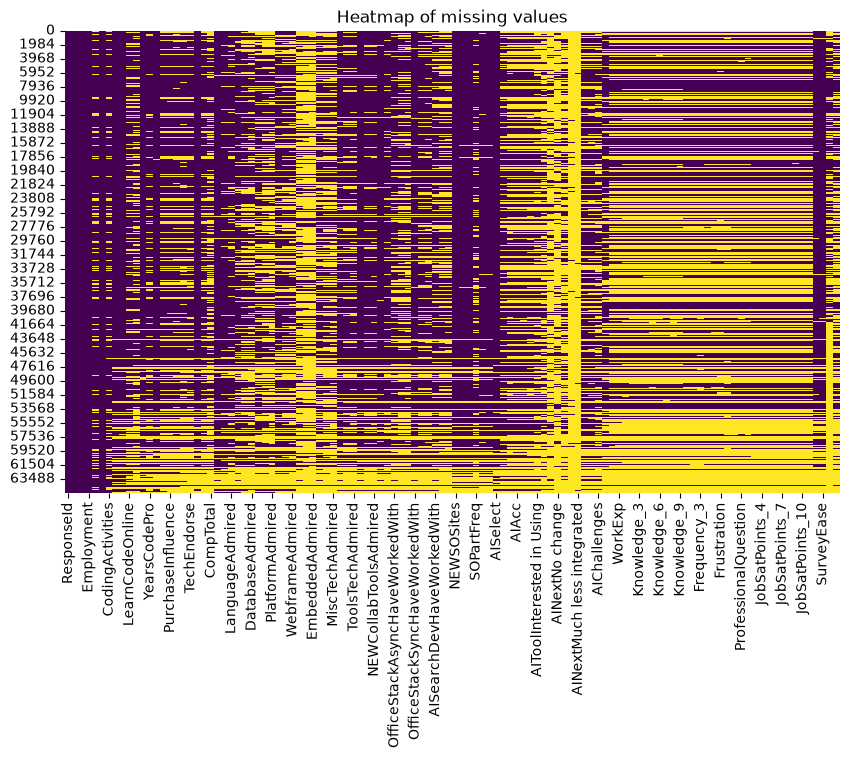

In [18]:
## Write your code here
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Heatmap of missing values")
plt.show()

##### Task 4: Count the number of missing rows for a specific column (e.g., `Employment`).


**Why focus on Employment?**<br>

Employment status is a categorical variable that could be useful when comparing respondent groups. Before filling in any values, I first check whether it has missing responses.

**Saved result:** 0 missing values.<br> This is important: the following imputation step demonstrates a technique, but it does not actually replace any missing Employment values in this dataset.

In [23]:
## Write your code here
missing_row_emp = df['Employment'].isnull().sum()
print(missing_row_emp)

0

### 4. Imputing Missing Values
##### Task 5: Identify the most frequent (majority) value in a specific column (e.g., `Employment`).


Understanding the most frequent value (mode)
For categorical data, the mode is the answer that appears most often. Mode imputation can sometimes be used to replace missing entries with a common category.

In the saved results, the most frequent employment category is Employed, full-time.

**Limitation:** Filling missing responses with the most common category can exaggerate its prevalence and hide meaningful differences between respondents. It should be justified rather than applied automatically.

In [24]:
## Write your code here
freq_employment = df['Employment'].mode()[0]
print("Most frequent value in column:", freq_employment)

Most frequent value in column: Employed, full-time

##### Task 6: Impute missing values in the `Employment` column with the most frequent value.



What does the imputation code do?
fillna(freq_employment) would replace missing entries in Employment with the most common category. Because the previous check found zero missing values, this operation leaves the column unchanged in the saved dataset. It demonstrates the syntax of categorical imputation, but it is not evidence that data quality improved in this run.

In [25]:
## Write your code here
df['Employment']=df['Employment'].fillna(freq_employment)

### 5. Visualizing Imputed Data
##### Task 7: Visualize the distribution of a column after imputation (e.g., `Employment`).


Why visualize the employment categories?
The horizontal bar chart makes the distribution of survey responses easier to compare than a long frequency table. The code groups less common categories into an Other category to keep the chart readable.

Since Employment had no missing values, this chart represents the original employment distribution, not a changed distribution after filling missing data.

**Reading the chart:** Longer bars represent more respondents in a category. These counts describe survey participants, not the overall labor market.

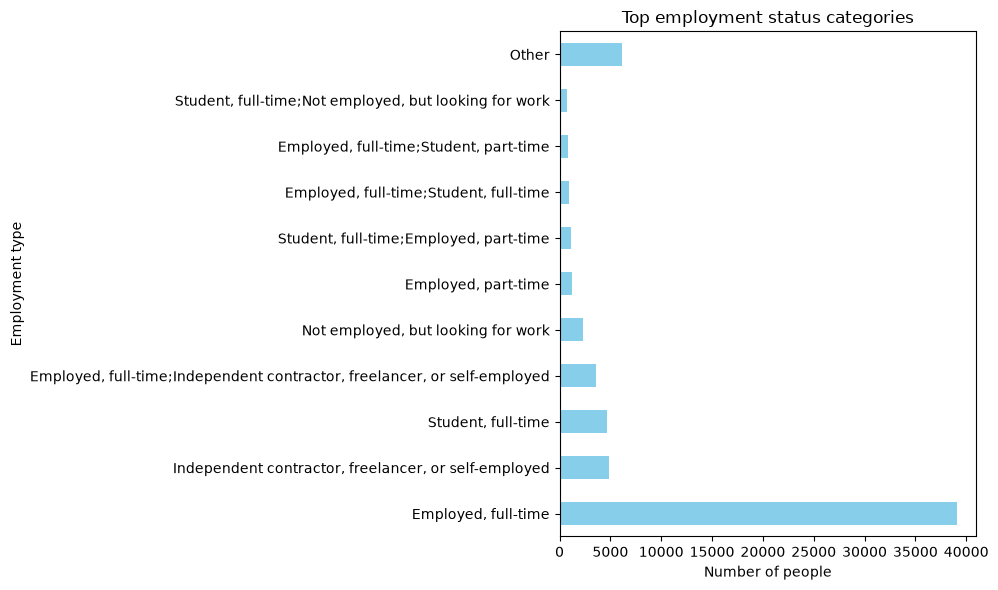

In [32]:
## Write your code here
top_categories = df['Employment'].value_counts().nlargest(10)
other_total = df['Employment'].value_counts().iloc[10:].sum()
cleaned_counts = pd.concat([top_categories, pd.Series({'Other': other_total})])

cleaned_counts.plot(kind='barh', color='skyblue', figsize=(10, 6))
plt.title("Top employment status categories")
plt.ylabel("Employment type")
plt.xlabel("Number of people")
plt.tight_layout()
plt.show()

### Key Findings and Interpretation
- The saved dataset contains 65,447 survey records and 114 fields.
- Missingness varies substantially across columns, including compensation and job satisfaction fields.
- The selected Employment field contains no missing values, so mode imputation makes no changes to it.
- The most frequent employment response is Employed, full-time.
- A missing-data strategy should depend on the meaning of the variable and why responses may be absent.

### Limitations and Next Steps
This guided exercise introduces missing-value detection and a simple imputation method; it does not establish why respondents skipped particular questions or whether imputation is appropriate for every column.

Possible next steps include calculating missing percentages, examining whether missingness is related to respondent groups, selecting a column that actually contains missing values for an imputation comparison, and documenting the effect of any replacements.

### Skills Demonstrated
- Data inspection: info(), describe() and dataset previews
- Data quality: isnull() and missing-value counts
- Data preparation: mode() and fillna()
- Visualization: Seaborn heatmaps and Pandas/Matplotlib bar charts
- Analytical communication: Explaining what the findings do and do not support

**Portfolio note:** The code and dataset originate from an IBM Skills Network guided lab. The additional project framing and interpretations are intended to make the workflow understandable to a wider audience. Saved outputs have not been independently rerun.

Copyright © IBM Corporation. All rights reserved.
